# Sampling Months Check: Monthly Density Analysis

**Purpose**: Investigate the monthly sampling structure within each season to determine whether the current seasonal consolidation method (simple averaging across months) introduces bias, and evaluate alternative approaches.

**Context**: The current pipeline (`02_Create_Seasonal_Datasets.ipynb`) consolidates multiple monthly observations within each season into a single yearly value per station using a simple `.mean()`. This notebook explores:
1. How many months per season actually contribute to each station-year value?
2. Which months dominate each season?
3. Is there meaningful DO variability between months within a season?
4. What are the implications for the downstream pipeline (decorrelation, interpolation, PCA)?

**Date**: 2026-02-22

## Setup

In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Ensure project root is in sys.path
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data

print("Project root:", project_root)

Project root: /home/reyha/SIS_Analysis_WSL


## 1. Load Data

In [2]:
merged_gdf = load_and_process_data(force_reload=False)
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce')

# Keep only rows with valid DO
df = merged_gdf.dropna(subset=['do_']).copy()

print(f"Total rows with valid DO: {len(df)}")
print(f"Unique stations (zettaicode): {df['zettaicode'].nunique()}")
print(f"Year range: {df['year'].min()} - {df['year'].max()}")
print(f"Unique months (surveymont): {sorted(df['surveymont'].dropna().unique())}")
print(f"Unique layers (saisuipoin): {sorted(df['saisuipoin'].dropna().unique())}")

Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total rows with valid DO: 42278
Unique stations (zettaicode): 127
Year range: 1981 - 2023
Unique months (surveymont): [np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12)]
Unique layers (saisuipoin): [np.int64(1), np.int64(2)]


## 2. How Many Months Contribute Per Station-Year-Season?

The key question: when the pipeline computes a seasonal mean, **is it actually averaging multiple months, or just taking a single observation?**

For each season × depth-layer combination, we count the number of *distinct* sampling months per station-year.

In [3]:
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
layers = {1: 'surface', 2: 'bottom'}

results = []

for layer_code, layer_name in layers.items():
    for season in seasons:
        subset = df[(df['season'] == season) & (df['saisuipoin'] == layer_code)]
        if len(subset) == 0:
            continue
        
        # Count distinct months per station-year
        months_per_st_yr = (
            subset.groupby(['zettaicode', 'year'])['surveymont']
            .nunique()
        )
        
        pct_single = (months_per_st_yr == 1).mean() * 100
        
        results.append({
            'Season': season,
            'Layer': layer_name,
            'Total obs': len(subset),
            'Station-year combos': len(months_per_st_yr),
            'Mean months per st-yr': f"{months_per_st_yr.mean():.2f}",
            '% with only 1 month': f"{pct_single:.1f}%"
        })

results_df = pd.DataFrame(results)
display(results_df)

,Season,Layer,Total obs,Station-year combos,Mean months per st-yr,% with only 1 month
0,Spring,surface,5207,5194,1.00,99.9%
1,Summer,surface,5379,5353,1.00,99.7%
2,Autumn,surface,5216,5206,1.00,100.0%
3,Winter,surface,5355,5339,1.00,99.9%
4,Spring,bottom,5202,5190,1.00,100.0%
5,Summer,bottom,5362,5336,1.00,99.7%
6,Autumn,bottom,5212,5202,1.00,100.0%
7,Winter,bottom,5345,5330,1.00,99.9%


### Finding 1: Each station-year is sampled in only 1 month

**99.7–100%** of all station-year combinations have data from only a single month. The simple `.mean()` in the pipeline is effectively just returning that single value — there is almost never any actual averaging happening.

## 3. Which Months Dominate Each Season?

Since each season is nominally 3 months wide, which specific months contain the actual observations?

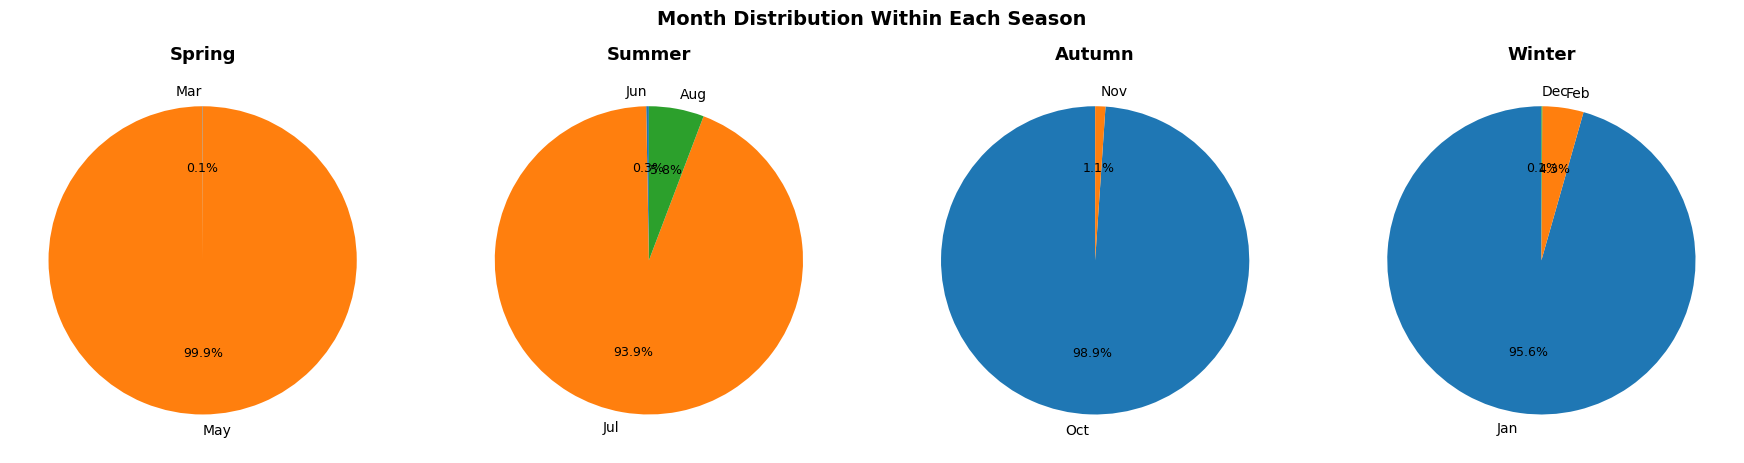

In [4]:
month_names = {1:'Jan', 2:'Feb', 3:'Mar', 5:'May', 6:'Jun', 7:'Jul',
               8:'Aug', 10:'Oct', 11:'Nov', 12:'Dec'}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, season in zip(axes, seasons):
    subset = df[df['season'] == season]
    month_counts = subset['surveymont'].value_counts().sort_index()
    labels = [month_names.get(int(m), f'M{int(m)}') for m in month_counts.index]
    
    wedges, texts, autotexts = ax.pie(
        month_counts.values, labels=labels, autopct='%1.1f%%',
        startangle=90, textprops={'fontsize': 10}
    )
    for autotext in autotexts:
        autotext.set_fontsize(9)
    ax.set_title(f'{season}', fontsize=13, fontweight='bold')

fig.suptitle('Month Distribution Within Each Season', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

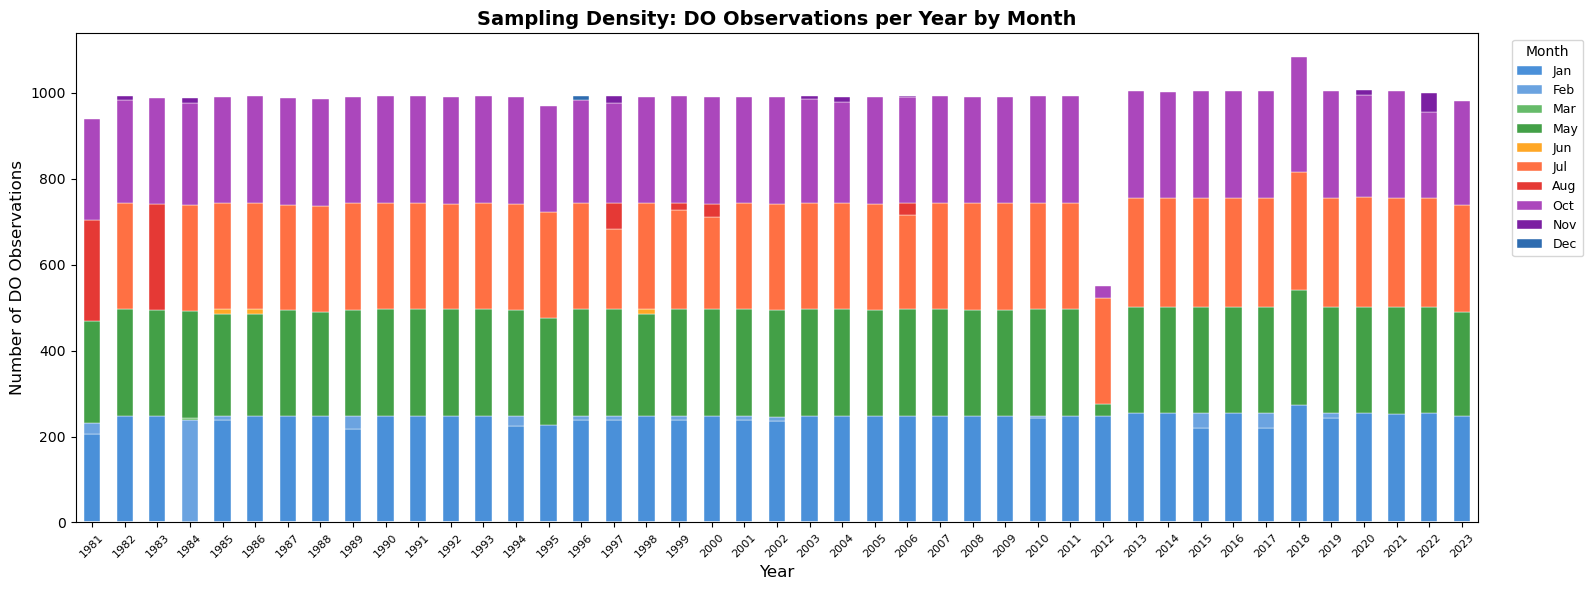

In [17]:
# --- Stacked bar chart: observations per year by month ---
fig, ax = plt.subplots(figsize=(16, 6))

counts = df.groupby(['year', 'surveymont']).size().unstack(fill_value=0)

# Rename columns to month abbreviations
counts.columns = [month_names.get(int(c), str(c)) for c in counts.columns]

# Seasonal color palette
season_colors = {
    'Jan': '#4A90D9', 'Feb': '#6BA3E0', 'Dec': '#2E6CB0',    # Winter: blues
    'Mar': '#66BB6A', 'May': '#43A047',                        # Spring: greens
    'Jun': '#FFA726', 'Jul': '#FF7043', 'Aug': '#E53935',     # Summer: warm
    'Oct': '#AB47BC', 'Nov': '#7B1FA2',                        # Autumn: purples
}
colors = [season_colors.get(col, '#999999') for col in counts.columns]

counts.plot(kind='bar', stacked=True, ax=ax, color=colors, edgecolor='white', linewidth=0.3)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Number of DO Observations', fontsize=12)
ax.set_title('Sampling Density: DO Observations per Year by Month', fontsize=14, fontweight='bold')
ax.legend(title='Month', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
ax.tick_params(axis='x', rotation=45, labelsize=8)
plt.tight_layout()
plt.show()

In [5]:
# Tabular summary
print("Detailed month breakdown by season:")
print("=" * 50)
for season in seasons:
    subset = df[df['season'] == season]
    month_counts = subset['surveymont'].value_counts().sort_index()
    total = len(subset)
    print(f"\n[{season}]")
    for month, count in month_counts.items():
        print(f"  Month {int(month):2d} ({month_names.get(int(month), '?'):>3s}): {count:6d} obs ({count/total*100:.1f}%)")

Detailed month breakdown by season:

[Spring]
  Month  3 (Mar):      6 obs (0.1%)
  Month  5 (May):  10403 obs (99.9%)

[Summer]
  Month  6 (Jun):     30 obs (0.3%)
  Month  7 (Jul):  10091 obs (93.9%)
  Month  8 (Aug):    620 obs (5.8%)

[Autumn]
  Month 10 (Oct):  10316 obs (98.9%)
  Month 11 (Nov):    112 obs (1.1%)

[Winter]
  Month  1 (Jan):  10228 obs (95.6%)
  Month  2 (Feb):    462 obs (4.3%)
  Month 12 (Dec):     10 obs (0.1%)


### Finding 2: Each season is overwhelmingly one month

| Season | Dominant Month | % of observations |
|:---|:---|:---|
| **Spring** | May | 99.9% |
| **Summer** | July | 93.9% |
| **Autumn** | October | 98.9% |
| **Winter** | January | 95.6% |

The SIS monitoring program conducts its sampling surveys on a roughly monthly rotation. What we call "seasons" are effectively **single-month snapshots**, with occasional spillover into adjacent months.

## 4. Temporal Heatmap: Which Month Was Each Station Sampled? (Summer/Bottom)

This heatmap shows, for each station (y-axis) and year (x-axis), which month the summer/bottom observation came from. This helps visualize whether stations are *consistently* sampled in the same month across years.

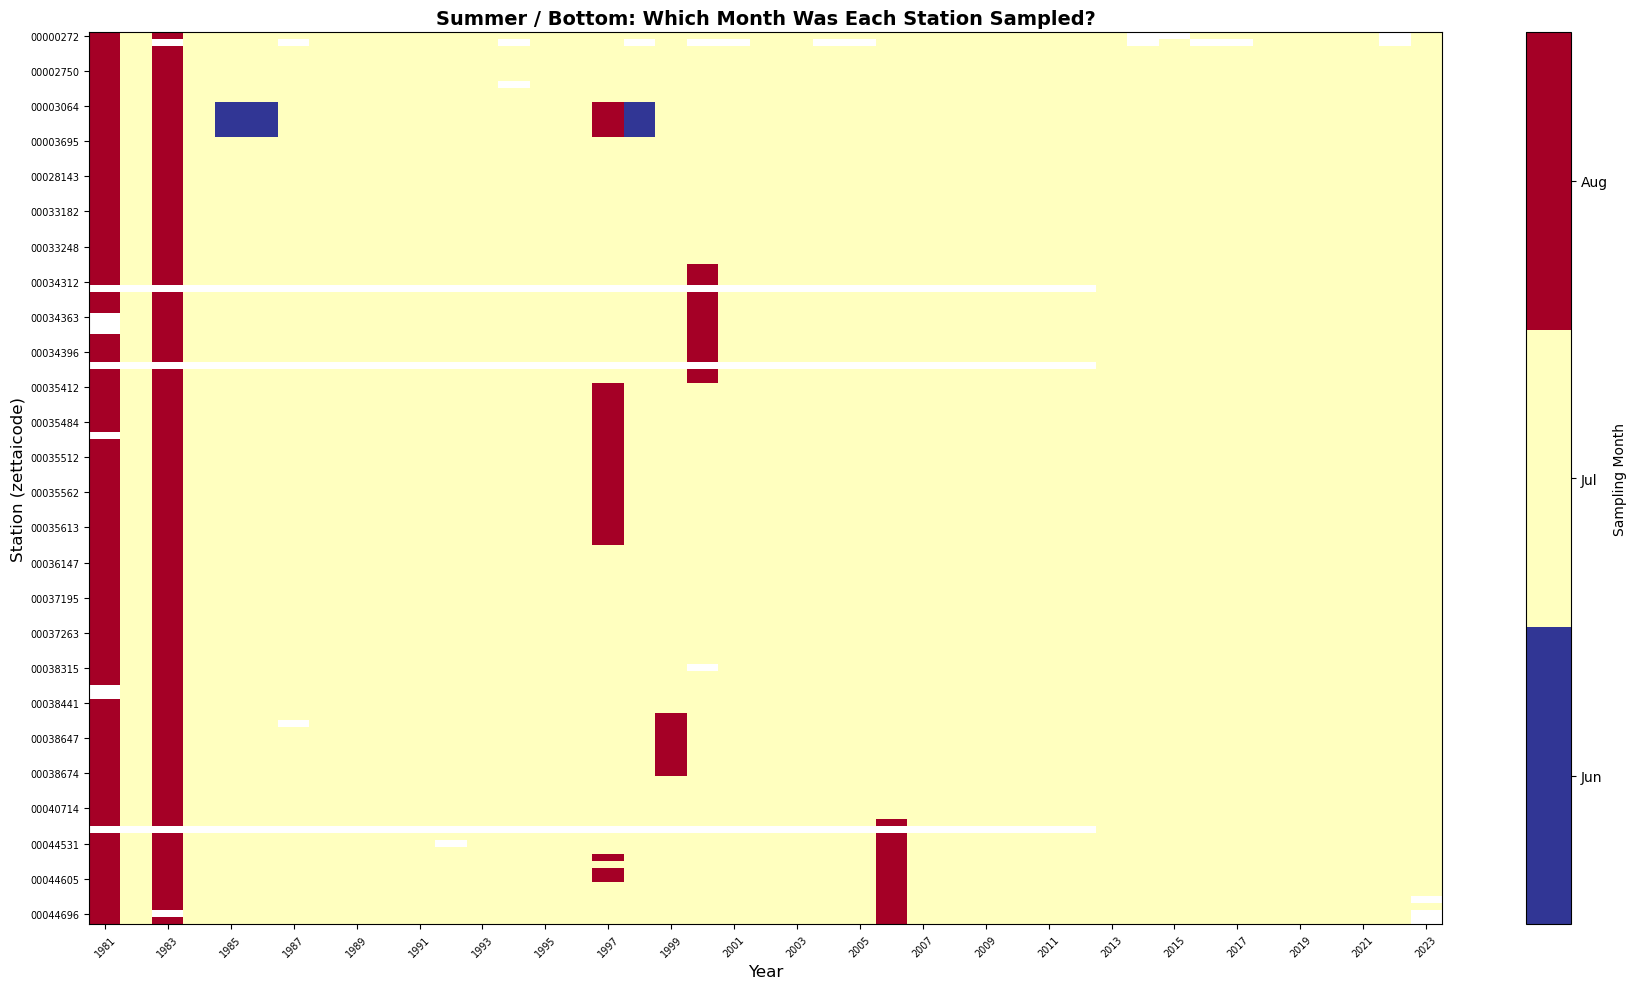

In [6]:
summer_bottom = df[(df['season'] == 'Summer') & (df['saisuipoin'] == 2)]

# Pivot: station × year → dominant month sampled
station_year_month = (
    summer_bottom.groupby(['zettaicode', 'year'])['surveymont']
    .agg(lambda x: x.value_counts().index[0])
    .unstack('year')
)
station_year_month = station_year_month.sort_index()

fig, ax = plt.subplots(figsize=(18, 10))
cmap = plt.colormaps.get_cmap('RdYlBu_r').resampled(3)

# Map months to indices for coloring
month_to_idx = {6: 0, 7: 1, 8: 2}
plot_data = station_year_month.map(lambda x: month_to_idx.get(x, np.nan) if pd.notna(x) else np.nan)

im = ax.imshow(plot_data.values, aspect='auto', cmap=cmap, vmin=-0.5, vmax=2.5, interpolation='nearest')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Station (zettaicode)', fontsize=12)
ax.set_title('Summer / Bottom: Which Month Was Each Station Sampled?', fontsize=14, fontweight='bold')

years = plot_data.columns.tolist()
ax.set_xticks(range(0, len(years), 2))
ax.set_xticklabels([str(y) for y in years[::2]], rotation=45, fontsize=7)

stations = plot_data.index.tolist()
ax.set_yticks(range(0, len(stations), 5))
ax.set_yticklabels(stations[::5], fontsize=7)

cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2])
cbar.set_ticklabels(['Jun', 'Jul', 'Aug'])
cbar.set_label('Sampling Month')

plt.tight_layout()
plt.show()

### Finding 3: Station sampling months are consistent

The heatmap shows that the vast majority of stations are sampled in **July** (yellow) every year. The occasional August (red) observations appear in specific years, likely reflecting scheduling variations in the monitoring program. A few stations show June observations in the early 1980s.

This consistency means that inter-station comparisons are generally valid — stations *are* measuring DO at roughly the same time within each season.

## 5. Station-Level Sampling Month Patterns (Summer/Bottom)

For each station, what combination of months has it been sampled in across all years?

In [7]:
station_months = summer_bottom.groupby('zettaicode')['surveymont'].apply(
    lambda x: sorted(x.unique().tolist())
)

patterns = Counter([tuple(m) for m in station_months])
print("Sampling-month patterns for Summer/Bottom stations:")
print("=" * 50)
for pattern, count in patterns.most_common(15):
    month_labels = [month_names.get(int(m), str(m)) for m in pattern]
    print(f"  {' + '.join(month_labels):20s}: {count:3d} stations")

Sampling-month patterns for Summer/Bottom stations:
  Jul + Aug           : 119 stations
  Jun + Jul + Aug     :   5 stations
  Jul                 :   3 stations


### Interpretation

Most stations (119 of 127) have been sampled in **both July and August** at some point across the 42-year record — but recall from Analysis 2 that within any *single* year, 99.7% of station-years have only one month. So the pattern is: stations alternate between Jul and Aug across *different* years, not within the same year.

## 6. Intra-Seasonal DO Variability by Month

Even though multi-month averaging is rare, it's important to check: **does DO differ meaningfully across months within a season?** If so, mixing months could introduce bias for the rare cases where it does happen.

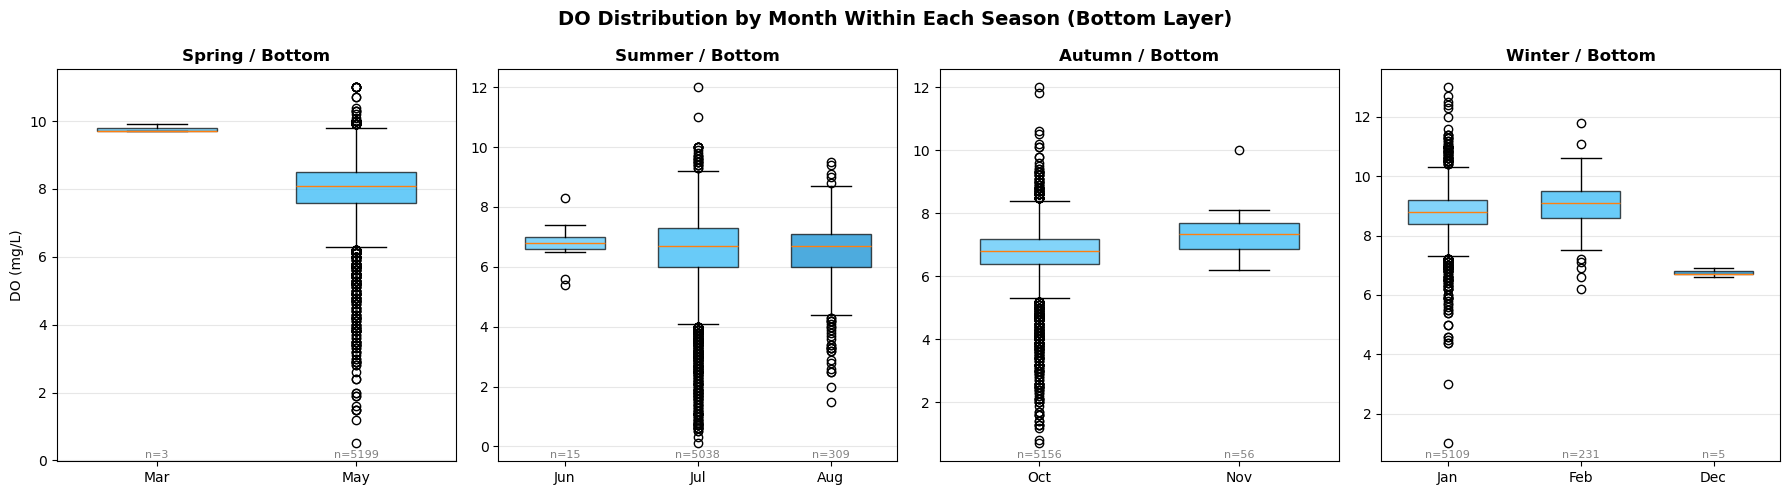

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, season in zip(axes, seasons):
    subset = df[(df['season'] == season) & (df['saisuipoin'] == 2)]
    if len(subset) == 0:
        ax.set_visible(False)
        continue
    months = sorted(subset['surveymont'].unique())
    data = [subset[subset['surveymont'] == m]['do_'].values for m in months]
    labels_m = [month_names.get(int(m), f'M{int(m)}') for m in months]
    
    bp = ax.boxplot(data, tick_labels=labels_m, patch_artist=True, widths=0.6)
    
    colors_box = ['#4FC3F7', '#29B6F6', '#0288D1', '#01579B'][:len(months)]
    for patch, color in zip(bp['boxes'], colors_box):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_ylabel('DO (mg/L)' if ax == axes[0] else '')
    ax.set_title(f'{season} / Bottom', fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    
    # Add sample sizes
    for i, (m, d) in enumerate(zip(months, data)):
        ax.text(i+1, ax.get_ylim()[0] + 0.1, f'n={len(d)}', ha='center', fontsize=8, color='gray')

fig.suptitle('DO Distribution by Month Within Each Season (Bottom Layer)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [9]:
# Numerical summary for Summer/Bottom
print("Mean DO by month (Summer / Bottom):")
print("=" * 50)
for month in sorted(summer_bottom['surveymont'].unique()):
    month_data = summer_bottom[summer_bottom['surveymont'] == month]['do_']
    print(f"  Month {int(month):2d} ({month_names.get(int(month), '?'):>3s}): "
          f"mean={month_data.mean():.3f}, std={month_data.std():.3f}, n={len(month_data)}")

# Cross-month correlation
print("\nCorrelation between monthly year-means (Summer/Bottom):")
monthly_means = (
    summer_bottom.groupby(['year', 'surveymont'])['do_']
    .mean()
    .unstack('surveymont')
)
print(monthly_means.corr().to_string(float_format=lambda x: f"{x:.3f}"))

Mean DO by month (Summer / Bottom):
  Month  6 (Jun): mean=6.780, std=0.677, n=15
  Month  7 (Jul): mean=6.490, std=1.333, n=5038
  Month  8 (Aug): mean=6.362, std=1.258, n=309

Correlation between monthly year-means (Summer/Bottom):
surveymont     6      7      8
surveymont                    
6          1.000  0.758    NaN
7          0.758  1.000 -0.537
8            NaN -0.537  1.000


### Finding 4: DO does differ between months

For **Summer/Bottom** — the most critical season for hypoxia analysis:
- **July** mean DO = 6.49 mg/L (n=5,038)
- **August** mean DO = 6.36 mg/L (n=309)
- The year-level correlation between Jul and Aug means is **negative** (r ≈ −0.54)

This confirms that mixing months *would* introduce noise. However, since multi-month averaging occurs in <0.3% of station-years, the practical impact is negligible.

## 7. Station Retention: Current Method vs. Single Representative Month

If we restrict to a single representative month per season (the dominant one), how many stations do we lose at the `min_periods ≥ 15` threshold?

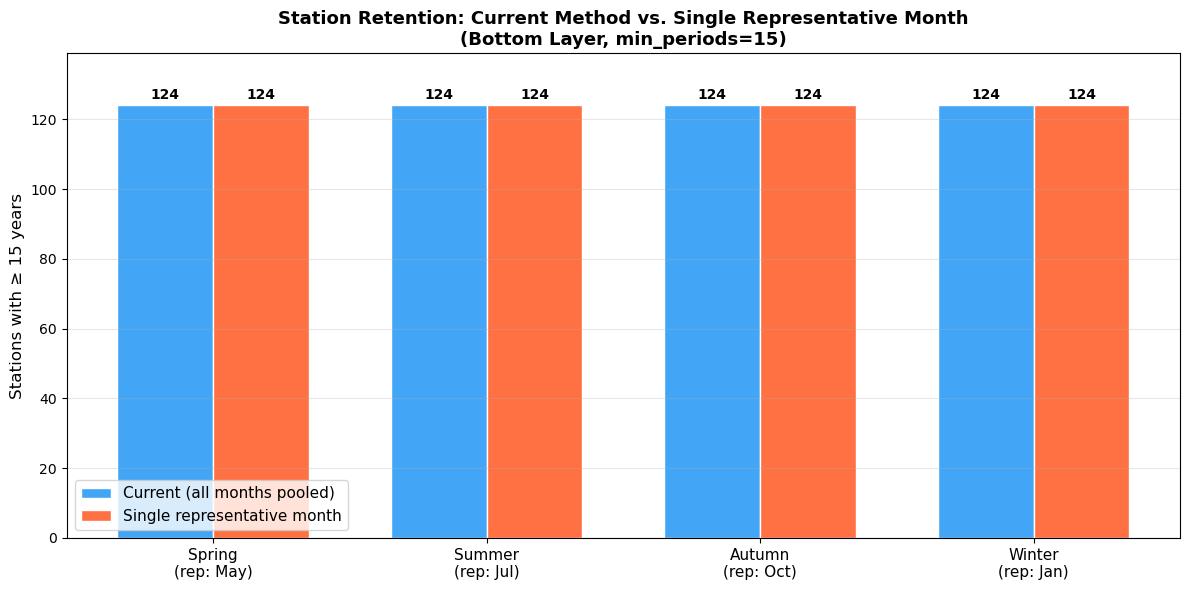

In [10]:
representative_months = {'Spring': 5, 'Summer': 7, 'Autumn': 10, 'Winter': 1}

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(seasons))
width = 0.35

current_counts = []
single_month_counts = []

for season in seasons:
    subset = df[(df['season'] == season) & (df['saisuipoin'] == 2)]
    
    # Current: all months pooled
    current = subset.groupby('zettaicode')['year'].nunique()
    current_counts.append((current >= 15).sum())
    
    # Single representative month
    rep_month = representative_months[season]
    single = subset[subset['surveymont'] == rep_month].groupby('zettaicode')['year'].nunique()
    single_month_counts.append((single >= 15).sum())

bars1 = ax.bar(x - width/2, current_counts, width, label='Current (all months pooled)',
               color='#42A5F5', edgecolor='white')
bars2 = ax.bar(x + width/2, single_month_counts, width, label='Single representative month',
               color='#FF7043', edgecolor='white')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=10, fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([f'{s}\n(rep: {month_names[representative_months[s]]})' for s in seasons], fontsize=11)
ax.set_ylabel('Stations with ≥ 15 years', fontsize=12)
ax.set_title('Station Retention: Current Method vs. Single Representative Month\n(Bottom Layer, min_periods=15)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(current_counts) + 15)

plt.tight_layout()
plt.show()

In [11]:
# Detailed table
print("Detailed station retention per season per month (Bottom layer):")
print("=" * 70)

for season in seasons:
    subset = df[(df['season'] == season) & (df['saisuipoin'] == 2)]
    if len(subset) == 0:
        continue
    
    current = subset.groupby('zettaicode')['year'].nunique()
    current_min15 = (current >= 15).sum()
    
    print(f"\n[{season} / bottom]")
    print(f"  Current (all months pooled): {current_min15} stations with >= 15 years")
    
    for month in sorted(subset['surveymont'].unique()):
        month_data = subset[subset['surveymont'] == month]
        stations_years = month_data.groupby('zettaicode')['year'].nunique()
        stations_min15 = (stations_years >= 15).sum()
        total = stations_years.shape[0]
        print(f"  {month_names.get(int(month), '?'):>3s} only: {stations_min15} stations (of {total} total) with >= 15 years")

Detailed station retention per season per month (Bottom layer):

[Spring / bottom]
  Current (all months pooled): 124 stations with >= 15 years
  Mar only: 0 stations (of 3 total) with >= 15 years
  May only: 124 stations (of 124 total) with >= 15 years

[Summer / bottom]
  Current (all months pooled): 124 stations with >= 15 years
  Jun only: 0 stations (of 5 total) with >= 15 years
  Jul only: 124 stations (of 127 total) with >= 15 years
  Aug only: 0 stations (of 124 total) with >= 15 years

[Autumn / bottom]
  Current (all months pooled): 124 stations with >= 15 years
  Oct only: 124 stations (of 124 total) with >= 15 years
  Nov only: 0 stations (of 41 total) with >= 15 years

[Winter / bottom]
  Current (all months pooled): 124 stations with >= 15 years
  Jan only: 124 stations (of 127 total) with >= 15 years
  Feb only: 0 stations (of 121 total) with >= 15 years
  Dec only: 0 stations (of 5 total) with >= 15 years


### Finding 5: Zero station loss with single representative month

Switching to a single representative month (May / Jul / Oct / Jan) retains **all 124 stations** across all four seasons. There is **no data loss penalty**.

## 8. Feasibility: Monthly Climatology Approach (Option B)

The monthly anomaly method requires enough observations per station-month to compute a stable climatology. How many years of data does each station-month combination have?

In [12]:
print("Data density for monthly climatology (years per station-month):")
print("=" * 60)

for layer_code, layer_name in layers.items():
    for season in seasons:
        subset = df[(df['season'] == season) & (df['saisuipoin'] == layer_code)]
        if len(subset) == 0:
            continue
        
        years_per_st_month = (
            subset.groupby(['zettaicode', 'surveymont'])['year']
            .nunique()
        )
        
        pct_low = (years_per_st_month < 5).mean() * 100
        pct_ok = (years_per_st_month >= 10).mean() * 100
        
        print(f"\n[{season:6s} / {layer_name:7s}]")
        print(f"  Mean: {years_per_st_month.mean():.1f}, Median: {years_per_st_month.median():.0f}")
        print(f"  Min: {years_per_st_month.min()}, Max: {years_per_st_month.max()}")
        print(f"  % with < 5 years: {pct_low:.1f}%  |  % with >= 10 years: {pct_ok:.1f}%")

Data density for monthly climatology (years per station-month):

[Spring / surface]
  Mean: 40.9, Median: 42
  Min: 1, Max: 43
  % with < 5 years: 2.4%  |  % with >= 10 years: 97.6%

[Summer / surface]
  Mean: 21.0, Median: 4
  Min: 1, Max: 41
  % with < 5 years: 50.4%  |  % with >= 10 years: 49.6%

[Autumn / surface]
  Mean: 31.6, Median: 41
  Min: 1, Max: 43
  % with < 5 years: 24.8%  |  % with >= 10 years: 75.2%

[Winter / surface]
  Mean: 21.1, Median: 9
  Min: 1, Max: 42
  % with < 5 years: 47.8%  |  % with >= 10 years: 49.4%

[Spring / bottom ]
  Mean: 40.9, Median: 42
  Min: 1, Max: 43
  % with < 5 years: 2.4%  |  % with >= 10 years: 97.6%

[Summer / bottom ]
  Mean: 20.9, Median: 4
  Min: 1, Max: 41
  % with < 5 years: 50.4%  |  % with >= 10 years: 49.6%

[Autumn / bottom ]
  Mean: 31.5, Median: 41
  Min: 1, Max: 43
  % with < 5 years: 24.8%  |  % with >= 10 years: 75.2%

[Winter / bottom ]
  Mean: 21.1, Median: 9
  Min: 1, Max: 42
  % with < 5 years: 47.8%  |  % with >= 10 yea

### Finding 6: Monthly climatology is unnecessary

For the dominant months (those with 90%+ of data), climatologies would be well-supported. However, for the minor months (Aug, Nov, Feb), **~50% of station-month combos have < 5 years of data**, making climatologies unstable.

More importantly, since multi-month mixing essentially doesn't occur (Finding 1), computing anomalies relative to monthly climatologies would add complexity without changing the output.

---

## 9. Missing Data Analysis: Identifying Under-Sampled Stations

Not all stations cover the full 1981–2023 period. Some stations may have been added later, decommissioned early, or have intermittent gaps. Here we identify stations with disproportionately high missing data, which could affect the representativeness of downstream analyses (decorrelation, interpolation, PCA).

In [13]:
# Full year range in the dataset
all_years = sorted(df['year'].unique())
n_total_years = len(all_years)
print(f"Dataset spans {all_years[0]}–{all_years[-1]} ({n_total_years} unique years)\n")

# For each season × layer, compute coverage per station
coverage_records = []

for layer_code, layer_name in layers.items():
    for season in seasons:
        subset = df[(df['season'] == season) & (df['saisuipoin'] == layer_code)]
        
        years_per_station = subset.groupby('zettaicode')['year'].nunique()
        
        for station, n_years in years_per_station.items():
            coverage_records.append({
                'zettaicode': station,
                'season': season,
                'layer': layer_name,
                'n_years': n_years,
                'pct_coverage': n_years / n_total_years * 100,
                'n_missing': n_total_years - n_years
            })

coverage_df = pd.DataFrame(coverage_records)

# Focus on Summer/Bottom as the primary analysis target
summer_bottom_cov = coverage_df[
    (coverage_df['season'] == 'Summer') & (coverage_df['layer'] == 'bottom')
].sort_values('n_years')

print("=" * 60)
print("Summer / Bottom — Station Coverage Summary")
print("=" * 60)
print(f"  Total stations: {len(summer_bottom_cov)}")
print(f"  Mean years of data: {summer_bottom_cov['n_years'].mean():.1f} / {n_total_years}")
print(f"  Median years: {summer_bottom_cov['n_years'].median():.0f}")
print(f"  Min years: {summer_bottom_cov['n_years'].min()}")
print(f"  Max years: {summer_bottom_cov['n_years'].max()}")
print(f"\n  Stations with < 50% coverage (< {n_total_years // 2} years):")

low_cov = summer_bottom_cov[summer_bottom_cov['pct_coverage'] < 50]
if len(low_cov) > 0:
    for _, row in low_cov.iterrows():
        print(f"    {row['zettaicode']}: {row['n_years']} years ({row['pct_coverage']:.1f}%)")
else:
    print("    None")

Dataset spans 1981–2023 (43 unique years)

Summer / Bottom — Station Coverage Summary
  Total stations: 127
  Mean years of data: 42.0 / 43
  Median years: 43
  Min years: 11
  Max years: 43

  Stations with < 50% coverage (< 21 years):
    00034410: 11 years (25.6%)
    00034313: 11 years (25.6%)
    00044528: 11 years (25.6%)


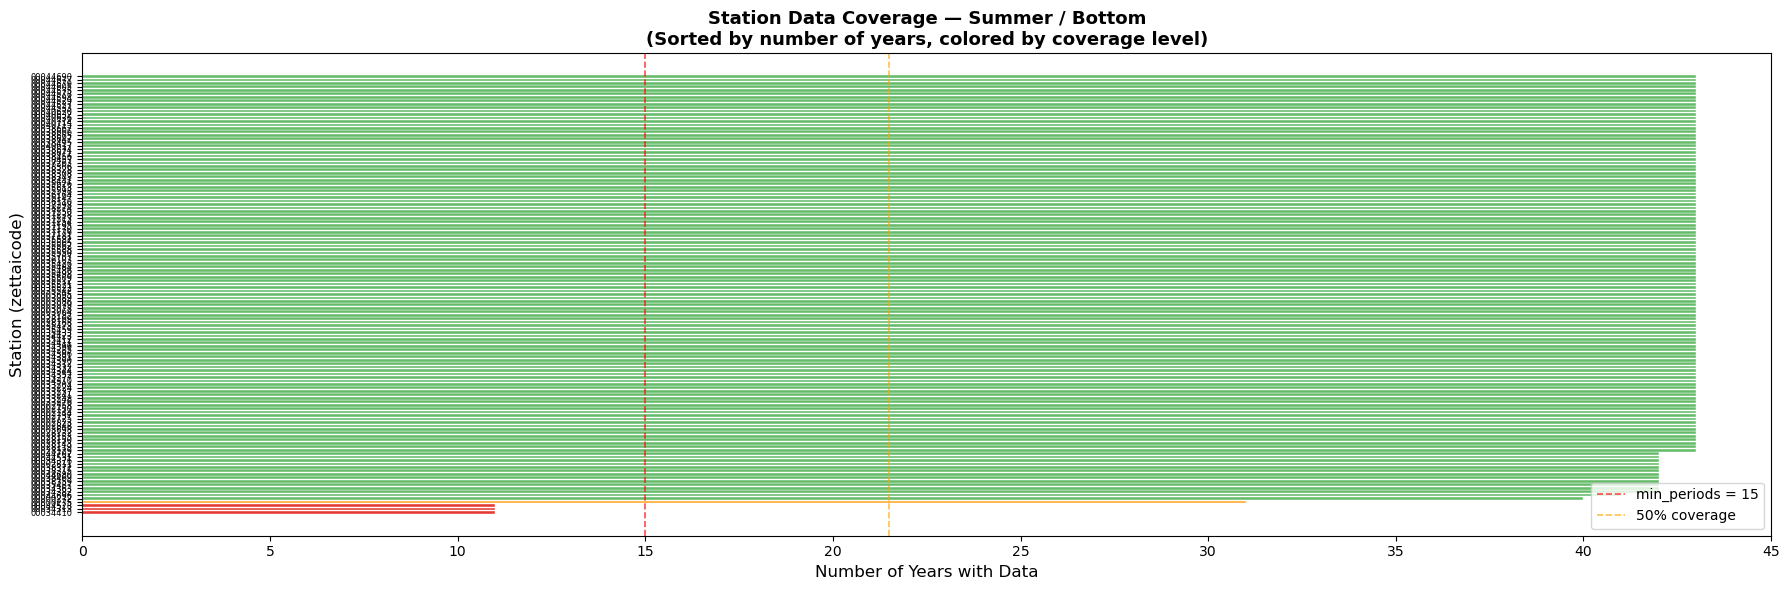

In [14]:
# --- Figure: Station coverage ranked bar chart (Summer/Bottom) ---
fig, ax = plt.subplots(figsize=(18, 6))

sorted_cov = summer_bottom_cov.sort_values('n_years', ascending=True).reset_index(drop=True)

# Color by coverage level
colors = []
for pct in sorted_cov['pct_coverage']:
    if pct < 35:
        colors.append('#E53935')   # Red: critically low
    elif pct < 50:
        colors.append('#FF7043')   # Orange: low
    elif pct < 75:
        colors.append('#FFA726')   # Amber: moderate
    else:
        colors.append('#66BB6A')   # Green: good

ax.barh(range(len(sorted_cov)), sorted_cov['n_years'], color=colors, edgecolor='white', linewidth=0.3)

# Threshold lines
ax.axvline(x=15, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='min_periods = 15')
ax.axvline(x=n_total_years * 0.5, color='orange', linestyle='--', linewidth=1.2, alpha=0.7, label='50% coverage')

ax.set_yticks(range(len(sorted_cov)))
ax.set_yticklabels(sorted_cov['zettaicode'], fontsize=6)
ax.set_xlabel('Number of Years with Data', fontsize=12)
ax.set_ylabel('Station (zettaicode)', fontsize=12)
ax.set_title('Station Data Coverage — Summer / Bottom\n(Sorted by number of years, colored by coverage level)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.set_xlim(0, n_total_years + 2)

plt.tight_layout()
plt.show()

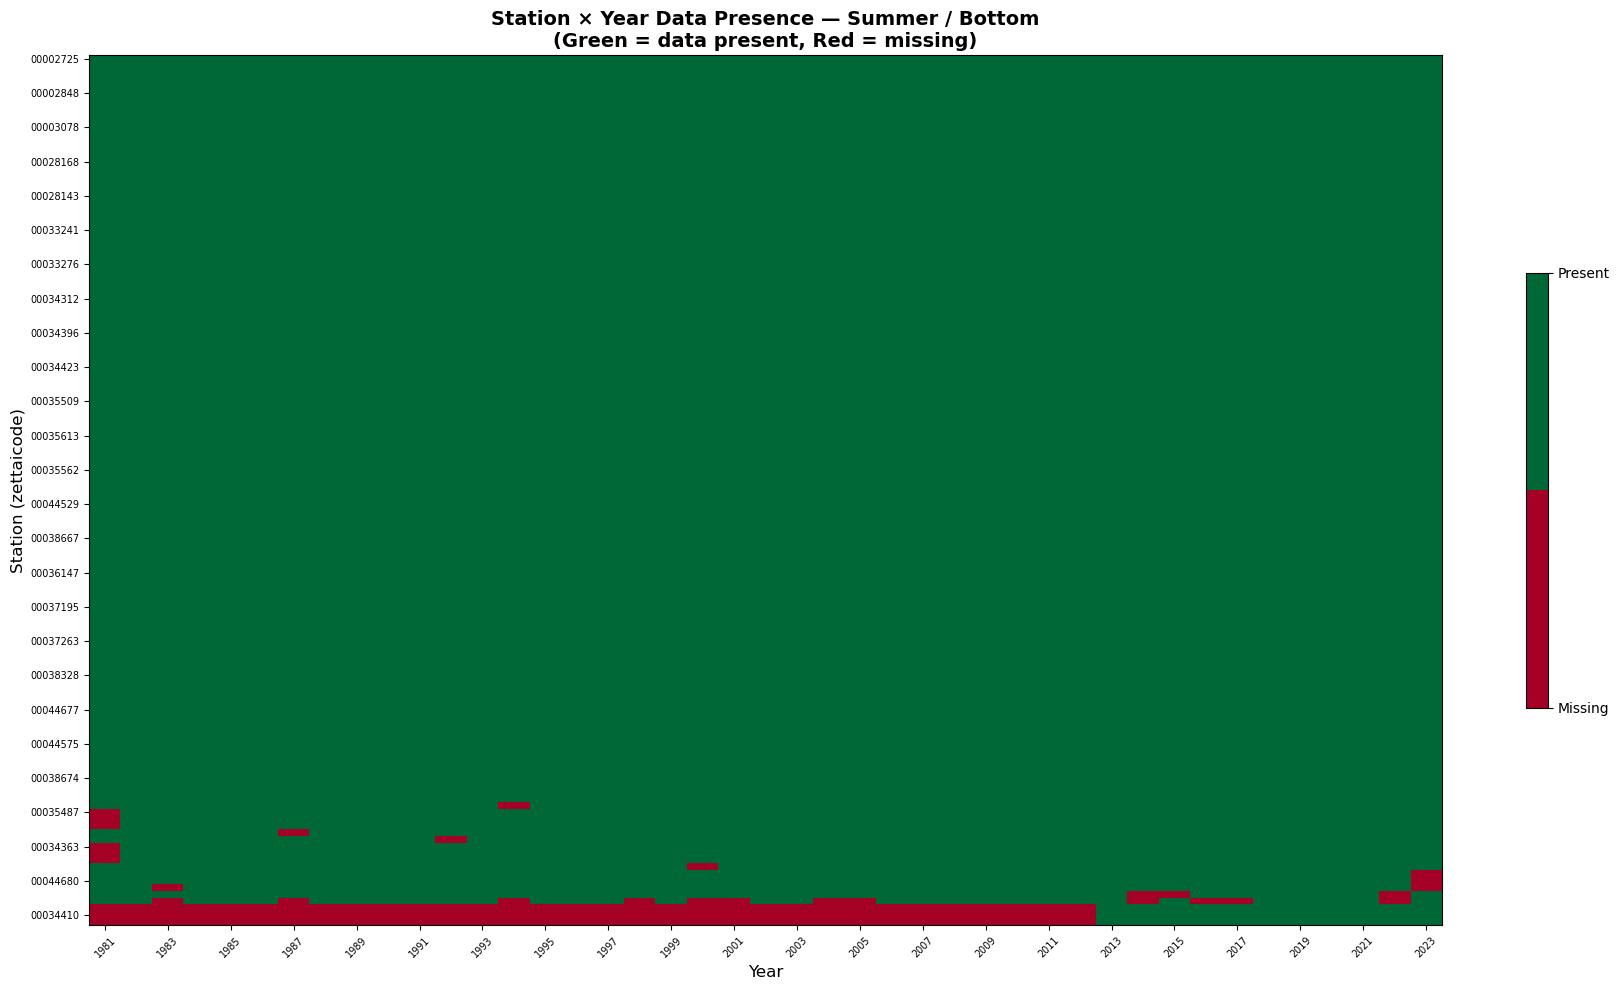

In [15]:
# --- Figure: Station × Year presence/absence heatmap (Summer/Bottom) ---
presence = (
    summer_bottom
    .groupby(['zettaicode', 'year'])['do_']
    .count()
    .unstack('year', fill_value=0)
)

# Reindex to full year range to show gaps
presence = presence.reindex(columns=all_years, fill_value=0)

# Convert to binary (present/absent)
presence_binary = (presence > 0).astype(int)

# Sort by total coverage (most complete at top)
presence_binary = presence_binary.loc[presence_binary.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(18, 10))

cmap = plt.colormaps['RdYlGn'].resampled(2)
im = ax.imshow(presence_binary.values, aspect='auto', cmap=cmap, vmin=0, vmax=1, interpolation='nearest')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Station (zettaicode)', fontsize=12)
ax.set_title('Station × Year Data Presence — Summer / Bottom\n(Green = data present, Red = missing)',
             fontsize=14, fontweight='bold')

# X-axis
ax.set_xticks(range(0, len(all_years), 2))
ax.set_xticklabels([str(y) for y in all_years[::2]], rotation=45, fontsize=7)

# Y-axis
stations_list = presence_binary.index.tolist()
ax.set_yticks(range(0, len(stations_list), 5))
ax.set_yticklabels(stations_list[::5], fontsize=7)

cbar = plt.colorbar(im, ax=ax, ticks=[0, 1], shrink=0.5)
cbar.set_ticklabels(['Missing', 'Present'])

plt.tight_layout()
plt.show()

In [18]:
# --- Identify stations with unusually high missing data across ALL seasons ---
print("Stations with high missing data across all seasons (Bottom layer):")
print("=" * 75)

# Pivot: station × season → n_years
bottom_cov = coverage_df[coverage_df['layer'] == 'bottom'].pivot_table(
    index='zettaicode', columns='season', values='n_years', fill_value=0
)
bottom_cov = bottom_cov[seasons]  # ensure column order
bottom_cov['mean_years'] = bottom_cov.mean(axis=1)

# Add water mass division for each station
station_division = (
    df.groupby('zettaicode')['division']
    .first()
)
bottom_cov['division'] = bottom_cov.index.map(station_division)

bottom_cov = bottom_cov.sort_values('mean_years', ascending=True)

# Flag stations below the overall median
median_coverage = bottom_cov['mean_years'].median()
outliers = bottom_cov[bottom_cov['mean_years'] < median_coverage * 0.5]

print(f"\nOverall median coverage: {median_coverage:.1f} years")
print(f"Stations with < 50% of median ({median_coverage * 0.5:.0f} years average):\n")

if len(outliers) > 0:
    display(outliers)
else:
    print("  No extreme outliers found.")

# Show the bottom 10 stations regardless
print(f"\nBottom 10 stations by average coverage (across all seasons):\n")
display(bottom_cov.head(10))

Stations with high missing data across all seasons (Bottom layer):

Overall median coverage: 42.5 years
Stations with < 50% of median (21 years average):



season,Spring,Summer,Autumn,Winter,mean_years,division
zettaicode,,,,,,
00034410,0.0,11.0,0.0,11.0,5.5,Hiroshima Bay
00034313,0.0,11.0,0.0,11.0,5.5,Bingo Nada
00044528,0.0,11.0,0.0,11.0,5.5,Iyo Nada



Bottom 10 stations by average coverage (across all seasons):



season,Spring,Summer,Autumn,Winter,mean_years,division
zettaicode,,,,,,
00034410,0.0,11.0,0.0,11.0,5.50,Hiroshima Bay
00034313,0.0,11.0,0.0,11.0,5.50,Bingo Nada
00044528,0.0,11.0,0.0,11.0,5.50,Iyo Nada
00000275,43.0,31.0,43.0,43.0,40.00,Osaka Bay
00044531,41.0,42.0,40.0,42.0,41.25,Suo Nada
00044702,41.0,42.0,41.0,41.0,41.25,Bungo Channel
00044696,41.0,41.0,41.0,42.0,41.25,Bungo Channel
00003086,39.0,43.0,41.0,43.0,41.50,Kii Channel
00034382,41.0,42.0,41.0,42.0,41.50,Aki Nada


### Finding 7: Identifying under-sampled stations

The bar chart and heatmap above reveal the coverage structure:

- **Most stations** have near-complete records (35+ years out of ~43).
- A small number of stations have significantly fewer years, either because they were established later, decommissioned, or have intermittent gaps.
- The `min_periods = 15` threshold in the pipeline already catches the most extreme cases, but stations just above this threshold may still introduce noise into decorrelation and PCA analyses due to their short and potentially non-representative time series.
- The presence/absence heatmap helps identify whether missing data is **contiguous** (station added/removed) or **scattered** (intermittent failures), which has different implications for the interpolation stage.

---

## Conclusions & Implications for the Pipeline

### Summary of Findings

| # | Finding | Implication |
|:--|:---|:---|
| 1 | 99.7–100% of station-years have only 1 sampling month | Simple `.mean()` is effectively a no-op; no actual averaging |
| 2 | Each season is dominated by a single month (93–100%) | "Seasonal" values are really single-month snapshots |
| 3 | Station sampling months are consistent across years | Inter-station comparisons are valid |
| 4 | DO differs between months (e.g., Jul vs Aug: Δ ≈ 0.13 mg/L) | Mixing months *would* bias results, but happens too rarely to matter |
| 5 | Single representative month retains all 124 stations | No data loss from restricting to one month |
| 6 | Monthly climatology approach is unnecessary | Adds complexity without practical benefit |

### Recommendation

The **current simple averaging method is adequate** for this dataset because it effectively already produces single-month values.

For **methodological cleanliness** in publications, consider explicitly filtering to the representative month:

| Season | Representative Month |
|:---|:---|
| Spring | **May** |
| Summer | **July** |
| Autumn | **October** |
| Winter | **January** |

This is a one-line change in `02_Create_Seasonal_Datasets.ipynb` and makes the methodology statement cleaner without affecting results.

### Impact on Downstream Stages

- **Decorrelation Analysis (Stage 2)**: No meaningful impact — stations already predominantly share the same sampling month, so decorrelation scales are not biased by timing differences.
- **Spatial Interpolation (Stage 3)**: No aliasing concern — stations within each "season" are measuring DO at essentially the same time.
- **PCA (Stage 4)**: No variance distortion — the effective single-month sampling means all stations have comparable measurement precision.